# UJIAN TENGAH SEMESTER (UTS) PEMBELAJARAN MESIN
* **Nama** : Dio Pramudya
* **NIM** : 202431058
* **Kelas** : Pembelajaran Mesin B
* **Model** : K-Nearest Neighbors (KNN) pada Dataset ISPU DKI Jakarta 2024

## 1. Import Library
Mengimpor seluruh pustaka (*library*) Python yang dibutuhkan untuk manipulasi data, visualisasi, *preprocessing*, pemodelan *K-Nearest Neighbors* (KNN), hingga evaluasi performa model.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

## 2. Memuat Dataset
Memuat dataset Indeks Standar Pencemar Udara (ISPU) Provinsi DKI Jakarta Tahun 2024 dalam format `.csv` menggunakan fungsi `pd.read_csv()`.

In [2]:
file_path = 'data-indeks-standar-pencemar-udara-(ispu)-di-provinsi-dki-jakarta-2024-komponen-data.csv'

df_raw = pd.read_csv(file_path)

# Menampilkan 5 baris pertama data
df_raw.head()

,periode_data,bulan,tanggal,stasiun,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max,parameter_pencemar_kritis,kategori
0,202401,1,21,DKI3 Jagakarsa,51.0,65.0,45.0,9.0,8.0,79.0,79.0,NaN,SEDANG
1,202401,1,27,DKI4 Lubang Buaya,38.0,47.0,24.0,5.0,11.0,10.0,47.0,PM25,BAIK
2,202401,1,26,DKI4 Lubang Buaya,58.0,77.0,27.0,7.0,16.0,14.0,77.0,PM25,SEDANG
3,202401,1,25,DKI4 Lubang Buaya,46.0,62.0,25.0,7.0,12.0,8.0,62.0,PM25,SEDANG
4,202401,1,24,DKI4 Lubang Buaya,46.0,61.0,24.0,6.0,7.0,6.0,61.0,PM25,SEDANG


## 3. Pemeriksaan Struktur Data Awal
Mengecek dimensi awal dataset, tipe data tiap kolom, jumlah dan persentase *missing value*, distribusi kelas target (`kategori`), serta jumlah baris duplikat identik.

In [4]:
print(f"Dimensi Data Awal : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")

Dimensi Data Awal : 1830 baris x 13 kolom


In [5]:
missing_summary = pd.DataFrame({
    'Tipe Data': df_raw.dtypes,
    'Jumlah Valid': df_raw.notna().sum(),
    'Jumlah Missing': df_raw.isna().sum(),
    'Persentase Missing (%)': (df_raw.isna().sum() / len(df_raw) * 100).round(2)
})
display(missing_summary)

,Tipe Data,Jumlah Valid,Jumlah Missing,Persentase Missing (%)
periode_data,int64,1830,0,0.00
bulan,int64,1830,0,0.00
tanggal,int64,1830,0,0.00
stasiun,object,1830,0,0.00
pm_sepuluh,float64,1695,135,7.38
pm_duakomalima,float64,1806,24,1.31
sulfur_dioksida,float64,1823,7,0.38
karbon_monoksida,float64,1815,15,0.82
ozon,float64,1823,7,0.38
nitrogen_dioksida,float64,1808,22,1.20


In [6]:
print(df_raw['kategori'].value_counts(dropna=False))
print(f"\nJumlah Baris Duplikat Identik Awal: {df_raw.duplicated().sum()}")

kategori
SEDANG                1522
BAIK                   160
TIDAK SEHAT            142
TIDAK ADA DATA           4
SANGAT TIDAK SEHAT       2
Name: count, dtype: int64

Jumlah Baris Duplikat Identik Awal: 650


## 4. Exploratory Data Analysis (EDA) & Deteksi Outlier
### Statistik Deskriptif & Perhitungan IQR
Menghitung nilai statistik deskriptif (Mean, Std, Min, Kuartil, Max) dan mendeteksi kandidat *outlier* pada 6 fitur polutan udara menggunakan metode **Interquartile Range (IQR)**:
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$

In [7]:
fitur_polutan = [
    'pm_sepuluh', 'pm_duakomalima', 'sulfur_dioksida',
    'karbon_monoksida', 'ozon', 'nitrogen_dioksida'
]

# Memastikan seluruh kolom polutan bertipe numerik (mengantisipasi karakter '-' pada CSV)
for col in fitur_polutan:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')

print("=== STATISTIK DESKRIPTIF & DETEKSI KANDIDAT OUTLIER (METODE IQR) ===")
iqr_rows = []
for col in fitur_polutan:
    s = df_raw[col].dropna()
    q1 = s.quantile(0.25)
    q2 = s.quantile(0.50)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((s < lower) | (s > upper)).sum()
    iqr_rows.append({
        'Fitur': col, 'Mean': round(s.mean(), 2), 'Std': round(s.std(), 2),
        'Min': s.min(), 'Q1': q1, 'Median': q2, 'Q3': q3, 'Max': s.max(),
        'IQR': iqr, 'Batas_Bawah': round(lower, 2), 'Batas_Atas': round(upper, 2),
        'Jml_Outlier': n_out, 'Outlier (%)': round(n_out / len(s) * 100, 2)
    })

df_iqr = pd.DataFrame(iqr_rows)
display(df_iqr)

=== STATISTIK DESKRIPTIF & DETEKSI KANDIDAT OUTLIER (METODE IQR) ===


,Fitur,Mean,Std,Min,Q1,Median,Q3,Max,IQR,Batas_Bawah,Batas_Atas,Jml_Outlier,Outlier (%)
0,pm_sepuluh,51.77,15.21,14.0,41.0,54.0,62.0,162.0,21.0,9.5,93.5,5,0.29
1,pm_duakomalima,71.25,22.72,10.0,56.0,74.0,87.0,157.0,31.0,9.5,133.5,5,0.28
2,sulfur_dioksida,39.29,18.48,3.0,19.0,47.0,55.0,112.0,36.0,-35.0,109.0,2,0.11
3,karbon_monoksida,16.57,7.57,3.0,10.0,15.0,22.0,45.0,12.0,-8.0,40.0,4,0.22
4,ozon,25.39,13.94,4.0,15.0,23.0,31.0,83.0,16.0,-9.0,55.0,90,4.94
5,nitrogen_dioksida,28.43,16.89,2.0,17.0,26.0,38.0,202.0,21.0,-14.5,69.5,31,1.71


### Visualisasi Distribusi Polutan dan Kelas Target
Membuat visualisasi *Boxplot* untuk melihat sebaran nilai dan *outlier* pada ke-6 parameter polutan, serta *Countplot* untuk melihat proporsi jumlah observasi pada setiap kategori mutu udara.

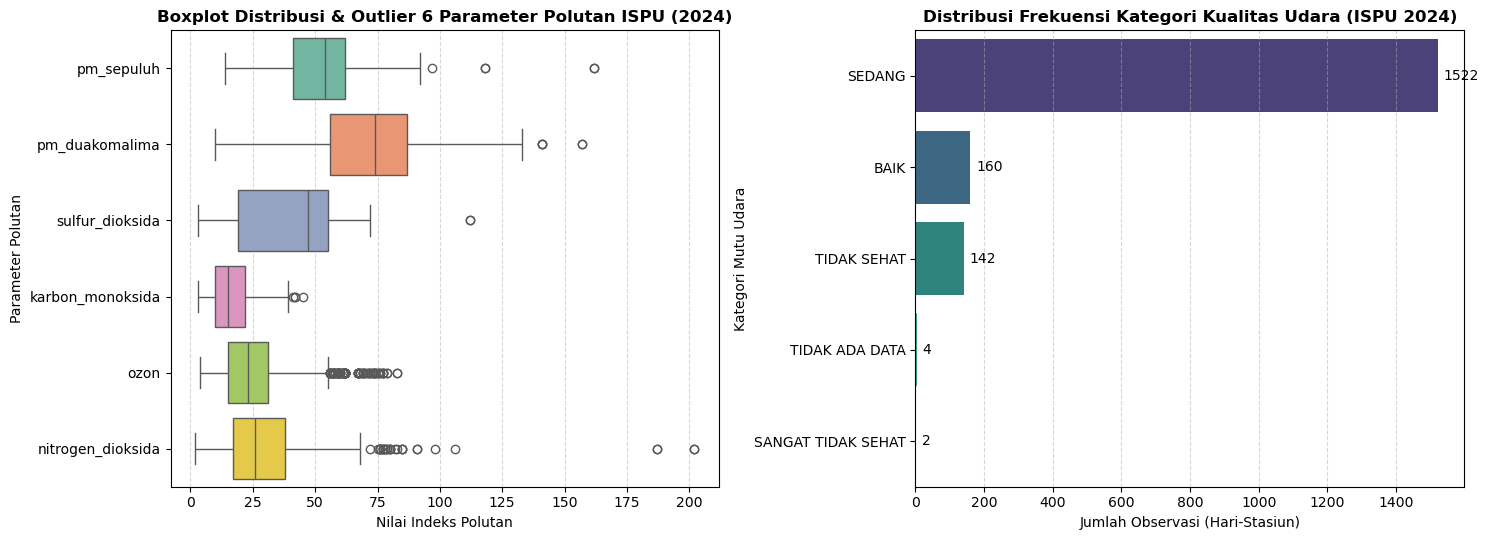

Grafik EDA berhasil disimpan sebagai 'visualisasi_eda_ispu.png'.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Grafik 1: Boxplot 6 Parameter Polutan
sns.boxplot(data=df_raw[fitur_polutan], orient='h', palette='Set2', ax=axes[0])
axes[0].set_title('Boxplot Distribusi & Outlier 6 Parameter Polutan ISPU (2024)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nilai Indeks Polutan')
axes[0].set_ylabel('Parameter Polutan')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Grafik 2: Distribusi Kategori Mutu Udara
urutan_kat = df_raw['kategori'].value_counts().index
sns.countplot(data=df_raw, y='kategori', order=urutan_kat, palette='viridis', ax=axes[1])
axes[1].set_title('Distribusi Frekuensi Kategori Kualitas Udara (ISPU 2024)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Observasi (Hari-Stasiun)')
axes[1].set_ylabel('Kategori Mutu Udara')
for container in axes[1].containers:
    axes[1].bar_label(container, padding=4)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('visualisasi_eda_ispu.png', dpi=300)
plt.show()
print("Grafik EDA berhasil disimpan sebagai 'visualisasi_eda_ispu.png'.")

## 5. Pembersihan Data (Data Cleaning) & Ekspor CSV Bersih
Tahapan pembersihan baris sebelum pembagian data:
1. Menghapus baris dengan label target `'TIDAK ADA DATA'` (karena seluruh sensor polutannya bernilai kosong/`NaN`).
2. Menstandarisasi penulisan nama stasiun pemantau yang tidak konsisten.
3. Menghapus baris duplikat identik dengan `drop_duplicates()`.
4. Menyimpan hasil dataset yang telah bersih ke dalam file CSV baru (`ispu_dki_jakarta_2024_clean.csv`).

In [9]:
df_clean = df_raw.copy()

# a) Hapus baris dengan kategori 'TIDAK ADA DATA' (seluruh polutan bernilai NaN)
df_clean = df_clean[df_clean['kategori'] != 'TIDAK ADA DATA'].copy()

# b) Standarisasi nama stasiun yang tidak konsisten
mapping_stasiun = {
    'DKI1 Bunderan HI': 'DKI1 Bundaran Hotel Indonesia (HI)',
    'DKI5 Kebon Jeruk Jakarta Barat': 'DKI5 Kebon Jeruk'
}
df_clean['stasiun'] = df_clean['stasiun'].replace(mapping_stasiun)

# c) Hapus duplikasi baris identik
jml_sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# d) Simpan data bersih ke file CSV baru
df_clean.to_csv('ispu_dki_jakarta_2024_clean.csv', index=False)

print("=== HASIL PEMBERSIHAN BARIS & DUPLIKASI ===")
print(f"Baris setelah hapus 'TIDAK ADA DATA' : {jml_sebelum}")
print(f"Baris unik setelah drop_duplicates() : {len(df_clean)}")
print("Data bersih berhasil disimpan ke 'ispu_dki_jakarta_2024_clean.csv'!")
print("\nDistribusi Kelas Target setelah Deduplikasi:")
print(df_clean['kategori'].value_counts())

=== HASIL PEMBERSIHAN BARIS & DUPLIKASI ===
Baris setelah hapus 'TIDAK ADA DATA' : 1826
Baris unik setelah drop_duplicates() : 1177
Data bersih berhasil disimpan ke 'ispu_dki_jakarta_2024_clean.csv'!

Distribusi Kelas Target setelah Deduplikasi:
kategori
SEDANG                973
BAIK                  112
TIDAK SEHAT            91
SANGAT TIDAK SEHAT      1
Name: count, dtype: int64


## 6. Penentuan Fitur (X) & Pembagian Data (Train-Test Split)
* **Pemilihan Fitur (`X`)**: Hanya menggunakan 6 parameter konsentrasi polutan. Kolom `max` dan `parameter_pencemar_kritis` sengaja **dibuang** agar tidak terjadi kebocoran informasi target (*Data Leakage*).
* **Pembagian Data**: Membagi dataset menjadi **80% Data Training** dan **20% Data Testing** menggunakan teknik *Stratified Split* (`stratify=y`) agar proporsi kelas minoritas tetap seimbang di kedua himpunan data.

In [12]:
# 1. Cek jumlah kemunculan tiap kelas
counts = df_clean['kategori'].value_counts()
print("Jumlah sampel per kategori:")
print(counts)

# 2. Ambil kategori yang memiliki anggota minimal 2
kelas_valid = counts[counts >= 2].index
df_filtered = df_clean[df_clean['kategori'].isin(kelas_valid)].copy()

# 3. Pisahkan X dan y
X = df_filtered[fitur_polutan].copy()
y = df_filtered['kategori'].copy()

# 4. Lakukan train_test_split dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nUkuran Data Training : {X_train.shape[0]} baris")
print(f"Ukuran Data Testing  : {X_test.shape[0]} baris")

Jumlah sampel per kategori:
kategori
SEDANG                973
BAIK                  112
TIDAK SEHAT            91
SANGAT TIDAK SEHAT      1
Name: count, dtype: int64

Ukuran Data Training : 940 baris
Ukuran Data Testing  : 236 baris


## 7. Pembuatan Pipeline & Pelatihan Model KNN
Membangun `Pipeline` untuk merangkai tiga tahapan sekaligus guna mencegah *Data Leakage* dari data uji:
1. **Imputasi Missing Value (`SimpleImputer`)**: Mengisi nilai kosong dengan **Median** dari `X_train` (tahan terhadap *outlier*).
2. **Normalisasi (`MinMaxScaler`)**: Menyamakan rentang nilai fitur ke skala $[0, 1]$ agar perhitungan jarak tidak didominasi oleh polutan berskala besar.
3. **Klasifikasi (`KNeighborsClassifier`)**: Melatih model KNN dengan parameter $K = 3$ dan metrik jarak **Euclidean**.

In [13]:
knn_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=3, metric='euclidean'))
])

# Pelatihan Model (Fitting) pada Data Training
knn_pipeline.fit(X_train, y_train)
print("Model KNeighborsClassifier (K=3, Euclidean) berhasil dilatih pada data training!")

# Menampilkan parameter yang dipelajari dari data training
imputer_fitted = knn_pipeline.named_steps['imputer']
scaler_fitted = knn_pipeline.named_steps['scaler']
param_df = pd.DataFrame({
    'Fitur': fitur_polutan,
    'Median_Train (Imputasi)': imputer_fitted.statistics_,
    'Min_Train (Scaler)': scaler_fitted.data_min_,
    'Max_Train (Scaler)': scaler_fitted.data_max_
})
print("\nParameter Preprocessing yang Dipelajari dari Data Training:")
display(param_df)

Model KNeighborsClassifier (K=3, Euclidean) berhasil dilatih pada data training!

Parameter Preprocessing yang Dipelajari dari Data Training:


,Fitur,Median_Train (Imputasi),Min_Train (Scaler),Max_Train (Scaler)
0,pm_sepuluh,54.0,14.0,162.0
1,pm_duakomalima,73.0,10.0,157.0
2,sulfur_dioksida,51.0,3.0,112.0
3,karbon_monoksida,14.0,3.0,42.0
4,ozon,21.0,5.0,83.0
5,nitrogen_dioksida,26.0,3.0,106.0


## 8. Prediksi & Evaluasi Performa Model
Menguji model yang telah dilatih pada **Data Testing** (`X_test`), menghitung metrik evaluasi klasifikasi multikelas (*Accuracy*, *Precision*, *Recall*, dan *F1-Score*), serta mengekspor hasil prediksi ke file CSV (`hasil_prediksi_knn.csv`).

In [14]:
# Prediksi pada Data Testing
y_pred = knn_pipeline.predict(X_test)

# Perhitungan Metrik Evaluasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=== HASIL EVALUASI MODEL KNN (K=3) PADA DATA TESTING ===")
print(f"Accuracy          : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Macro) : {prec_macro:.4f}")
print(f"Recall (Macro)    : {rec_macro:.4f}")
print(f"F1-Score (Macro)  : {f1_macro:.4f}")
print(f"F1-Score (Weight) : {f1_weighted:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, zero_division=0))

# Menyimpan hasil prediksi data testing ke file CSV
df_hasil_uji = X_test.copy()
df_hasil_uji['Kategori_Aktual'] = y_test.values
df_hasil_uji['Kategori_Prediksi'] = y_pred
df_hasil_uji.to_csv('hasil_prediksi_knn.csv', index=False)
print("Hasil prediksi data testing berhasil disimpan ke 'hasil_prediksi_knn.csv'!")

=== HASIL EVALUASI MODEL KNN (K=3) PADA DATA TESTING ===
Accuracy          : 0.9110 (91.10%)
Precision (Macro) : 0.8401
Recall (Macro)    : 0.7610
F1-Score (Macro)  : 0.7962
F1-Score (Weight) : 0.9076

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        BAIK       0.79      0.65      0.71        23
      SEDANG       0.93      0.96      0.95       195
 TIDAK SEHAT       0.80      0.67      0.73        18

    accuracy                           0.91       236
   macro avg       0.84      0.76      0.80       236
weighted avg       0.91      0.91      0.91       236

Hasil prediksi data testing berhasil disimpan ke 'hasil_prediksi_knn.csv'!


## 9. Visualisasi Confusion Matrix & Kurva Sensitivitas Nilai K
Membuat visualisasi **Confusion Matrix** untuk mengamati detail ketepatan dan kesalahan klasifikasi antar kelas, serta grafik perbandingan akurasi *training* vs *testing* pada berbagai nilai $K$ ganjil ($K = 1, 3, \dots, 15$).

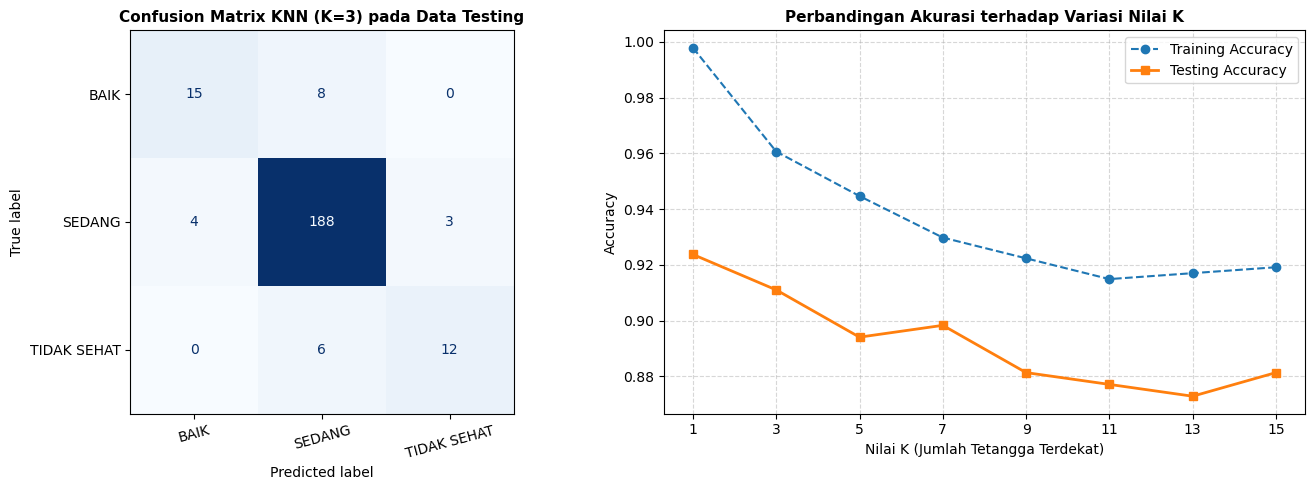

Grafik evaluasi model berhasil disimpan sebagai 'evaluasi_model_knn.png'.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Plot Confusion Matrix
labels_order = ['BAIK', 'SEDANG', 'TIDAK SEHAT', 'SANGAT TIDAK SEHAT']
labels_present = [l for l in labels_order if l in np.unique(np.concatenate([y_test, y_pred]))]
cm = confusion_matrix(y_test, y_pred, labels=labels_present)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_present)
disp.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix KNN (K=3) pada Data Testing', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

# 2. Plot Evaluasi Sensitivitas Nilai K
k_values = range(1, 16, 2)
train_scores = []
test_scores = []
for k in k_values:
    pipe_k = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, metric='euclidean'))
    ])
    pipe_k.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, pipe_k.predict(X_train)))
    test_scores.append(accuracy_score(y_test, pipe_k.predict(X_test)))

axes[1].plot(k_values, train_scores, marker='o', label='Training Accuracy', linestyle='--')
axes[1].plot(k_values, test_scores, marker='s', label='Testing Accuracy', linewidth=2)
axes[1].set_title('Perbandingan Akurasi terhadap Variasi Nilai K', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Nilai K (Jumlah Tetangga Terdekat)')
axes[1].set_ylabel('Accuracy')
axes[1].set_xticks(list(k_values))
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('evaluasi_model_knn.png', dpi=300)
plt.show()
print("Grafik evaluasi model berhasil disimpan sebagai 'evaluasi_model_knn.png'.")

## 10. Verifikasi Perhitungan Manual (Soal 2)
Membuktikan keakuratan perhitungan manual pada Soal 2 menggunakan 9 sampel data latih dan 1 sampel data uji pada 4 fitur (`pm_sepuluh`, `pm_duakomalima`, `karbon_monoksida`, `ozon`) dengan parameter $K = 3$ dan jarak Euclidean.

In [17]:
idx_latih = [0, 1, 2, 6, 8, 9, 10, 51, 52]
idx_uji = [3]
fitur_manual = ['pm_sepuluh', 'pm_duakomalima', 'karbon_monoksida', 'ozon']

X_man_train = df_raw.loc[idx_latih, fitur_manual].values
y_man_train = df_raw.loc[idx_latih, 'kategori'].values
X_man_test = df_raw.loc[idx_uji, fitur_manual].values

knn_man = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_man.fit(X_man_train, y_man_train)
distances, indices = knn_man.kneighbors(X_man_test)
pred_man = knn_man.predict(X_man_test)[0]

print(f"3 Tetangga Terdekat (Urutan Sampel) : {indices[0] + 1}")
print(f"Jarak Euclidean 3 Tetangga Terdekat : {np.round(distances[0], 4)}")
print(f"Prediksi Model KNN Manual (K=3)     : {pred_man} (Aktual: {df_raw.loc[3, 'kategori']})")

3 Tetangga Terdekat (Urutan Sampel) : [1 7 2]
Jarak Euclidean 3 Tetangga Terdekat : [ 7.3485 12.083  17.1464]
Prediksi Model KNN Manual (K=3)     : SEDANG (Aktual: SEDANG)
